In [5]:
import pandas as pd
import os
print(os.listdir('Downloads/Exam_Dataset'))


['.ipynb_checkpoints', 'Mall_Customers.csv', 'POP.csv', 'Q3_Mall_Customers_Done', 'Titanic.csv']


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('Downloads/Exam_Dataset/Pop.csv',header=None,skiprows=5,usecols=[0,1,3,4])
print("Shape:",df.shape)
df.head()

Shape: (324, 4)


,0,1,3,4
0,IND,1,India,"1,417,173"
1,CHN,2,China,"1,412,175"
2,USA,3,United States,"333,288"
3,IDN,4,Indonesia,"275,501"
4,PAK,5,Pakistan,"235,825"


C:\Users\zach


In [5]:
df=pd.read_csv('Downloads/Exam_Dataset/Pop.csv',header=3)
print("Shape:",df.shape)
print(df.head())
df.info()

Shape: (325, 6)
  Unnamed: 0 Ranking  Unnamed: 2        Economy  (thousands) Unnamed: 5
0        NaN     NaN         NaN            NaN          NaN        NaN
1        IND       1         NaN          India   1,417,173         NaN
2        CHN       2         NaN          China   1,412,175         NaN
3        USA       3         NaN  United States     333,288         NaN
4        IDN       4         NaN      Indonesia     275,501         NaN
<class 'pandas.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   229 non-null    str    
 1   Ranking      219 non-null    str    
 2   Unnamed: 2   0 non-null      float64
 3   Economy      229 non-null    str    
 4   (thousands)  229 non-null    str    
 5   Unnamed: 5   2 non-null      str    
dtypes: float64(1), str(5)
memory usage: 20.7 KB


In [7]:
import pandas as pd

#1.LOAD
df=pd.read_csv('Downloads/Exam_Dataset/Pop.csv',header=3)

#2.DIMENSIONS-rows and columns
print("DIMENSIONS")
print(df.shape)
print(df.columns)

#3.DATA TYPES
print("DATA TYPES")
print(df.dtypes)
df.info()

#4.MISSING VALUES
print("MISSING VALUES")
print(df.isnull().sum())

#5.DUPLICATES
print("DUPLICATES")
print(df.duplicated().sum())

print("HEAD")
print(df.head(10))

DIMENSIONS
(325, 6)
Index(['Unnamed: 0', 'Ranking', 'Unnamed: 2', 'Economy', '(thousands)',
       'Unnamed: 5'],
      dtype='str')
DATA TYPES
Unnamed: 0         str
Ranking            str
Unnamed: 2     float64
Economy            str
(thousands)        str
Unnamed: 5         str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 325 entries, 0 to 324
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   229 non-null    str    
 1   Ranking      219 non-null    str    
 2   Unnamed: 2   0 non-null      float64
 3   Economy      229 non-null    str    
 4   (thousands)  229 non-null    str    
 5   Unnamed: 5   2 non-null      str    
dtypes: float64(1), str(5)
memory usage: 20.7 KB
MISSING VALUES
Unnamed: 0      96
Ranking        106
Unnamed: 2     325
Economy         96
(thousands)     96
Unnamed: 5     323
dtype: int64
DUPLICATES
93
HEAD
  Unnamed: 0 Ranking  Unnamed: 2             Economy  (thousands)

In [14]:
#.DATA WRANGLING



#2.Rename columns for clarity
df.columns=['Country_Code','Rank','Country','Population_thousands']

#3.Handle missing values-drop rows with no country or population
df=df.dropna(subset=['Country','Population_thousands'])

#4.Drop duplicates
df=df.drop_duplicates()

#5.Convert to numbers-remove commas first
df['Population_thousands']=df['Population_thousands'].astype(str).str.replace(',','',regex=False)
df['Population_thousands']=pd.to_numeric(df['Population_thousands'],errors='coerce')
df['Rank']=pd.to_numeric(df['Rank'],errors='coerce')                                                                       

print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.head(10))
print(df.isnull().sum())

(229, 4)
Index(['Country_Code', 'Rank', 'Country', 'Population_thousands'], dtype='str')
Country_Code                str
Rank                    float64
Country                     str
Population_thousands      int64
dtype: object
  Country_Code  Rank             Country  Population_thousands
0          IND   1.0               India               1417173
1          CHN   2.0               China               1412175
2          USA   3.0       United States                333288
3          IDN   4.0           Indonesia                275501
4          PAK   5.0            Pakistan                235825
5          NGA   6.0             Nigeria                218541
6          BRA   7.0              Brazil                215313
7          BGD   8.0          Bangladesh                171186
8          RUS   9.0  Russian Federation                143556
9          MEX  10.0              Mexico                127504
Country_Code             0
Rank                    12
Country               

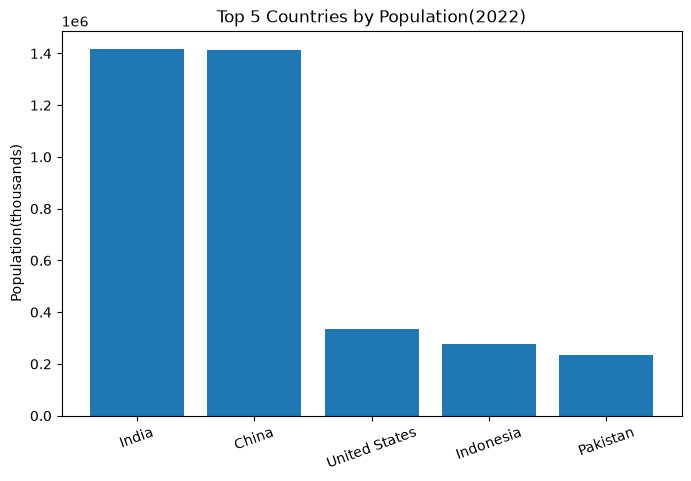

In [16]:
import matplotlib.pyplot as plt

top5=df.head(5)

plt.figure(figsize=(8,5))
plt.bar(top5['Country'],top5['Population_thousands'])
plt.title('Top 5 Countries by Population(2022)')
plt.ylabel('Population(thousands)')
plt.xticks(rotation=20)
plt.show()

<Figure size 500x400 with 0 Axes>

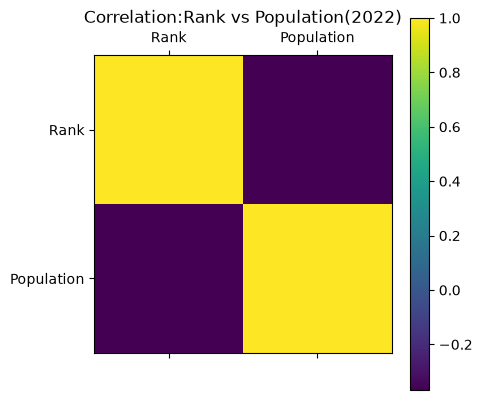

In [21]:

import matplotlib.pyplot as plt

corr=df[['Rank','Population_thousands']].corr()

plt.figure(figsize=(5,4))
plt.matshow(corr)
plt.colorbar()
plt.xticks([0,1],['Rank','Population'])
plt.yticks([0,1],['Rank','Population'])
plt.title('Correlation:Rank vs Population(2022)')
plt.show()